## 1. Import libraries and dataset

In [1]:
import joblib
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE, BorderlineSMOTE

# Mô hình
import lightgbm as lgb
import xgboost as xgb
from imblearn.ensemble import BalancedRandomForestClassifier



# Đánh giá
from sklearn.metrics import (
    classification_report,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)
from sklearn.base import clone

# Đường dẫn đến thư mục chứa dữ liệu đã xử lý
DATA_PATH = r'D:\AI66A_group_10_Topic_7\src\data\processed'

In [2]:

def load_data(path):
    X_train = joblib.load(os.path.join(path, 'X_train.pkl'))
    y_train = joblib.load(os.path.join(path, 'y_train.pkl'))
    X_test = joblib.load(os.path.join(path, 'X_test.pkl'))
    y_test = joblib.load(os.path.join(path, 'y_test.pkl'))
    X_val = joblib.load(os.path.join(path, "X_val.pkl"))
    y_val = joblib.load(os.path.join(path, 'y_val.pkl'))
    feature_cols = joblib.load(os.path.join(path, 'feature_cols.pkl'))
    return X_train, y_train, X_test, y_test, X_val, y_val, feature_cols

X_train, y_train, X_test, y_test, X_val, y_val, feature_cols = load_data(DATA_PATH)
print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Validation set: {X_val.shape}")


Training set: (416250, 28)
Test set: (89197, 28)
Validation set: (89197, 28)


In [3]:
lgb_best_params = {
    'n_estimators': 1588,
    'max_depth': 8,
    'learning_rate': 0.011111730153570632,
    'num_leaves': 262,
    'min_child_samples': 6,
    'subsample': 0.7675345232911098,
    'colsample_bytree': 0.5125626108583482,
    'scale_pos_weight': 5.084119553737549,
    'n_jobs': -1,
    'random_state': 42,
}

xgb_best_params = {
    'n_estimators': 1373,
    'max_depth': 8,
    'learning_rate': 0.0070295261563991405,
    'subsample': 0.9973124683007342,
    'colsample_bytree': 0.5225725607254758,
    'min_child_weight': 13,
    'scale_pos_weight': 5.084119553737549,
    "n_jobs": -1,
    'random_state': 42,
}


brf_best_params = {
    'n_estimators': 1279,
    'max_depth': 12,
    'min_samples_leaf': 8,
    'min_samples_split': 8,
    'max_features': 'sqrt',
    'n_jobs': -1,
    'bootstrap': True,
    "random_state": 42
}

In [4]:
lgb_model = lgb.LGBMClassifier(**lgb_best_params)
xgb_model = xgb.XGBClassifier(**xgb_best_params)
brf_model = BalancedRandomForestClassifier(**brf_best_params)

In [22]:
# Resample toàn bộ train set
X_train_res, y_train_res = SMOTE(sampling_strategy=0.1).fit_resample(X_train, y_train)

# Train trên full train set đã resample
lgb_model.fit(X_train_res, y_train_res)
xgb_model.fit(X_train_res, y_train_res)
brf_model.fit(X_train_res, y_train_res)

[LightGBM] [Info] Number of positive: 41098, number of negative: 410984
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012168 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6289
[LightGBM] [Info] Number of data points in the train set: 452082, number of used features: 28
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.090908 -> initscore=-2.302595
[LightGBM] [Info] Start training from score -2.302595
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best g

BalancedRandomForestClassifier(bootstrap=True, max_depth=12, min_samples_leaf=8,
                               min_samples_split=8, n_estimators=1279,
                               n_jobs=-1, random_state=42)

In [6]:
# Lấy predictions từ 3 model final (train trên full train set)
pred_lgb = lgb_model.predict_proba(X_test)[:, 1]
pred_xgb = xgb_model.predict_proba(X_test)[:, 1]
pred_brf = brf_model.predict_proba(X_test)[:, 1]

# Soft voting: trung bình probability
final_pred_proba = (pred_lgb + pred_xgb + pred_brf) / 3

# Tìm threshold tối ưu F2 trên val set
from sklearn.metrics import fbeta_score
import numpy as np

thresholds = np.arange(0.1, 0.9, 0.01)
f2_scores = []

pred_val_lgb = lgb_model.predict_proba(X_val)[:, 1]
pred_val_xgb = xgb_model.predict_proba(X_val)[:, 1]
pred_val_brf = brf_model.predict_proba(X_val)[:, 1]
val_proba = (pred_val_lgb + pred_val_xgb + pred_val_brf) / 3

for t in thresholds:
    preds = (val_proba > t).astype(int)
    f2 = fbeta_score(y_val, preds, beta=2)
    f2_scores.append(f2)

best_threshold = thresholds[np.argmax(f2_scores)]
print(f"Best threshold: {best_threshold:.2f}")
print(f"Best F2: {max(f2_scores):.4f}")

# Apply threshold lên test set
final_pred = (final_pred_proba > best_threshold).astype(int)

c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Best threshold: 0.37
Best F2: 0.8715


In [7]:
from sklearn.metrics import classification_report, average_precision_score

print(f"PR-AUC: {average_precision_score(y_test, final_pred_proba):.4f}")
print(classification_report(y_test, final_pred))

PR-AUC: 0.9215
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     88235
           1       0.71      0.92      0.81       962

    accuracy                           1.00     89197
   macro avg       0.86      0.96      0.90     89197
weighted avg       1.00      1.00      1.00     89197



## 3. Visualization for ensemble evaluation

In [8]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    precision_score,
    recall_score,
    fbeta_score,
)

val_prob_dict = {
    'LightGBM': pred_val_lgb,
    'XGBoost': pred_val_xgb,
    'BalancedRandomForest': pred_val_brf,
    'Ensemble': val_proba,
}

test_prob_dict = {
    'LightGBM': pred_lgb,
    'XGBoost': pred_xgb,
    'BalancedRandomForest': pred_brf,
    'Ensemble': final_pred_proba,
}

threshold_search = {}
best_thresholds = {}
test_pred_dict = {}
comparison_rows = []

for model_name, val_prob in val_prob_dict.items():
    model_records = []
    for t in thresholds:
        val_pred = (val_prob > t).astype(int)
        model_records.append({
            'threshold': t,
            'f2': fbeta_score(y_val, val_pred, beta=2, zero_division=0),
            'precision': precision_score(y_val, val_pred, zero_division=0),
            'recall': recall_score(y_val, val_pred, zero_division=0),
        })

    threshold_df = pd.DataFrame(model_records)
    best_idx = threshold_df['f2'].idxmax()
    best_t = float(threshold_df.loc[best_idx, 'threshold'])
    best_thresholds[model_name] = best_t
    threshold_search[model_name] = threshold_df

    test_prob = test_prob_dict[model_name]
    test_pred = (test_prob > best_t).astype(int)
    test_pred_dict[model_name] = test_pred

    comparison_rows.append({
        'Model': model_name,
        'PR-AUC': average_precision_score(y_test, test_prob),
        'ROC-AUC': roc_auc_score(y_test, test_prob),
        'F2': fbeta_score(y_test, test_pred, beta=2, zero_division=0),
        'Threshold': best_t,
        'Precision': precision_score(y_test, test_pred, zero_division=0),
        'Recall': recall_score(y_test, test_pred, zero_division=0),
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(['PR-AUC', 'F2'], ascending=False).reset_index(drop=True)
comparison_df

,Model,PR-AUC,ROC-AUC,F2,Threshold,Precision,Recall
0,XGBoost,0.924936,0.998865,0.870414,0.29,0.699060,0.927235
1,LightGBM,0.921923,0.998792,0.856359,0.11,0.696414,0.908524
2,Ensemble,0.921461,0.998665,0.871488,0.37,0.714746,0.922037
3,BalancedRandomForest,0.875167,0.998051,0.847904,0.55,0.613188,0.937630


### 3.1 Precision-Recall Curve

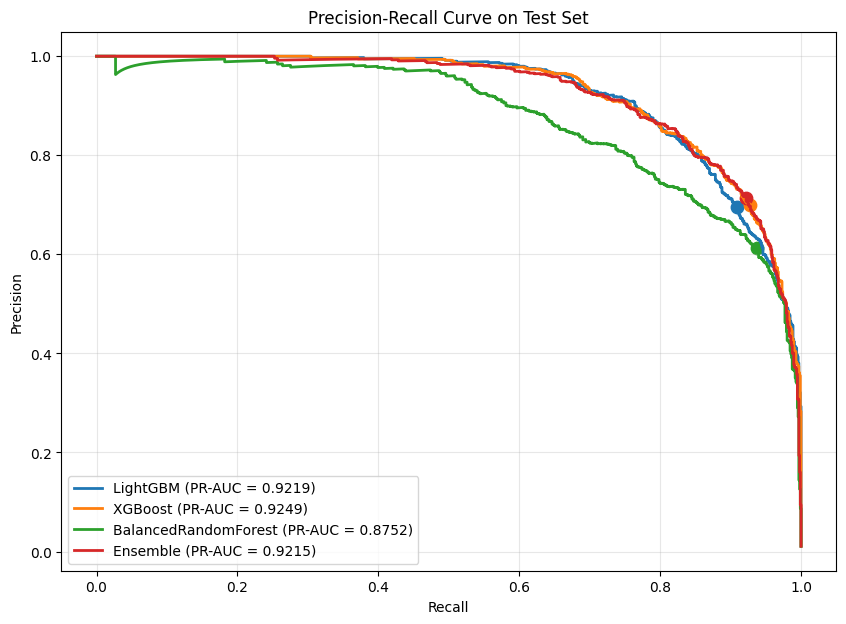


Models Thresholds: 


,Best Threshold
LightGBM,0.11
XGBoost,0.29
BalancedRandomForest,0.55
Ensemble,0.37


In [21]:
plt.figure(figsize=(10, 7))

for model_name, test_prob in test_prob_dict.items():
    precision, recall, _ = precision_recall_curve(y_test, test_prob)
    pr_auc = average_precision_score(y_test, test_prob)
    plt.plot(recall, precision, linewidth=2, label=f"{model_name} (PR-AUC = {pr_auc:.4f})")

    y_pred = test_pred_dict[model_name]
    best_precision = precision_score(y_test, y_pred, zero_division=0)
    best_recall = recall_score(y_test, y_pred, zero_division=0)
    plt.scatter(best_recall, best_precision, s=80)

plt.title('Precision-Recall Curve on Test Set')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.grid(alpha=0.3)
plt.legend()
plt.show()
print("\nModels Thresholds: ")
pd.DataFrame.from_dict(best_thresholds, orient='index', columns=["Best Threshold"])



### 3.2 F2-Score vs Threshold

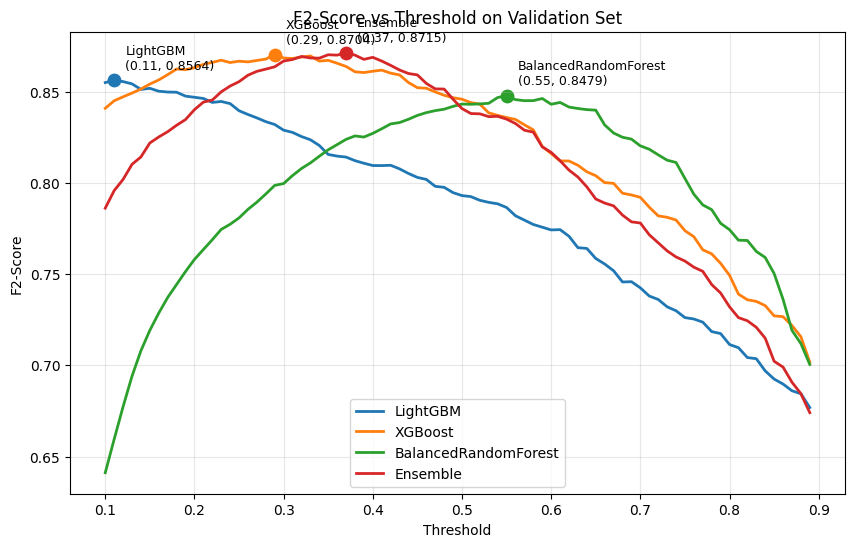

In [10]:
plt.figure(figsize=(10, 6))

for model_name, threshold_df in threshold_search.items():
    plt.plot(threshold_df['threshold'], threshold_df['f2'], linewidth=2, label=model_name)
    best_row = threshold_df.loc[threshold_df['f2'].idxmax()]
    plt.scatter(best_row['threshold'], best_row['f2'], s=80)
    plt.annotate(
        f"{model_name}\n({best_row['threshold']:.2f}, {best_row['f2']:.4f})",
        (best_row['threshold'], best_row['f2']),
        textcoords='offset points',
        xytext=(8, 8),
        fontsize=9,
    )

plt.title('F2-Score vs Threshold on Validation Set')
plt.xlabel('Threshold')
plt.ylabel('F2-Score')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 3.3 Confusion Matrix

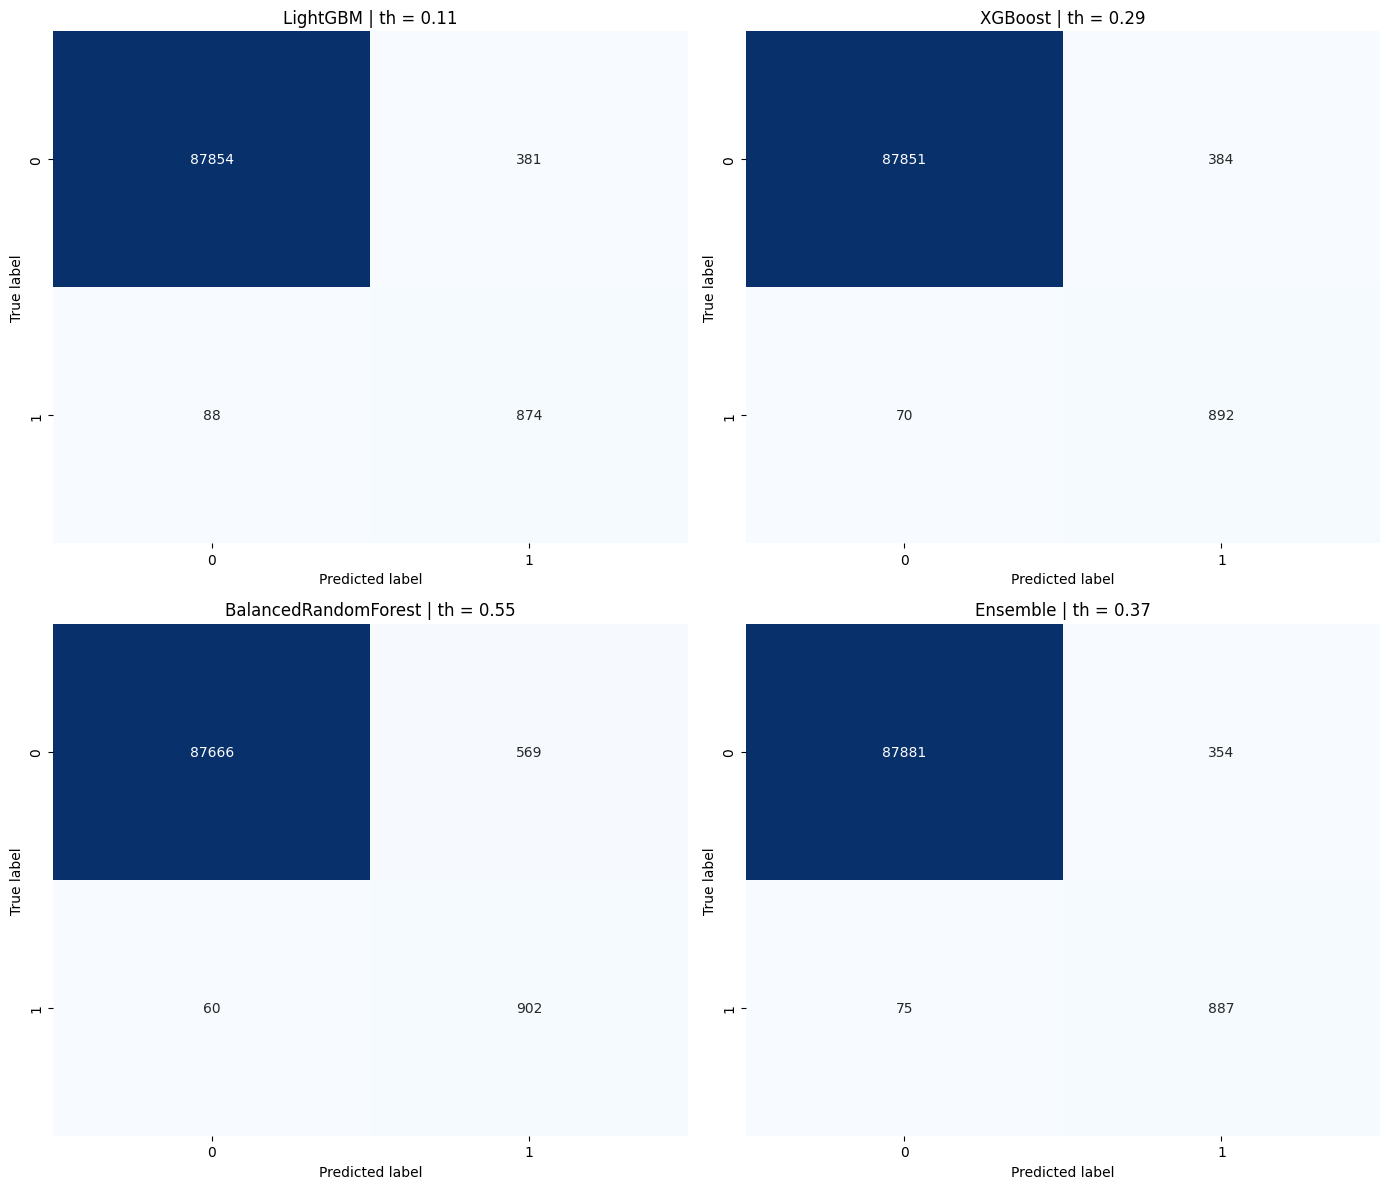

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for ax, model_name in zip(axes, test_prob_dict.keys()):
    cm = confusion_matrix(y_test, test_pred_dict[model_name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(f"{model_name} | th = {best_thresholds[model_name]:.2f}")
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')

plt.tight_layout()
plt.show()

### 3.4 ROC Curve

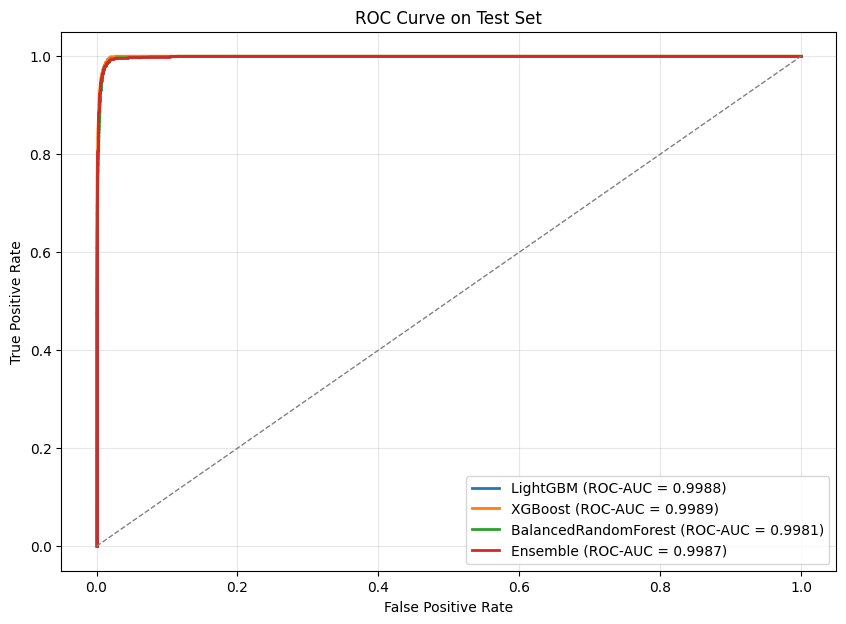

In [12]:
plt.figure(figsize=(10, 7))

for model_name, test_prob in test_prob_dict.items():
    fpr, tpr, _ = roc_curve(y_test, test_prob)
    roc_auc = roc_auc_score(y_test, test_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f"{model_name} (ROC-AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
plt.title('ROC Curve on Test Set')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 3.5 Probability Distribution

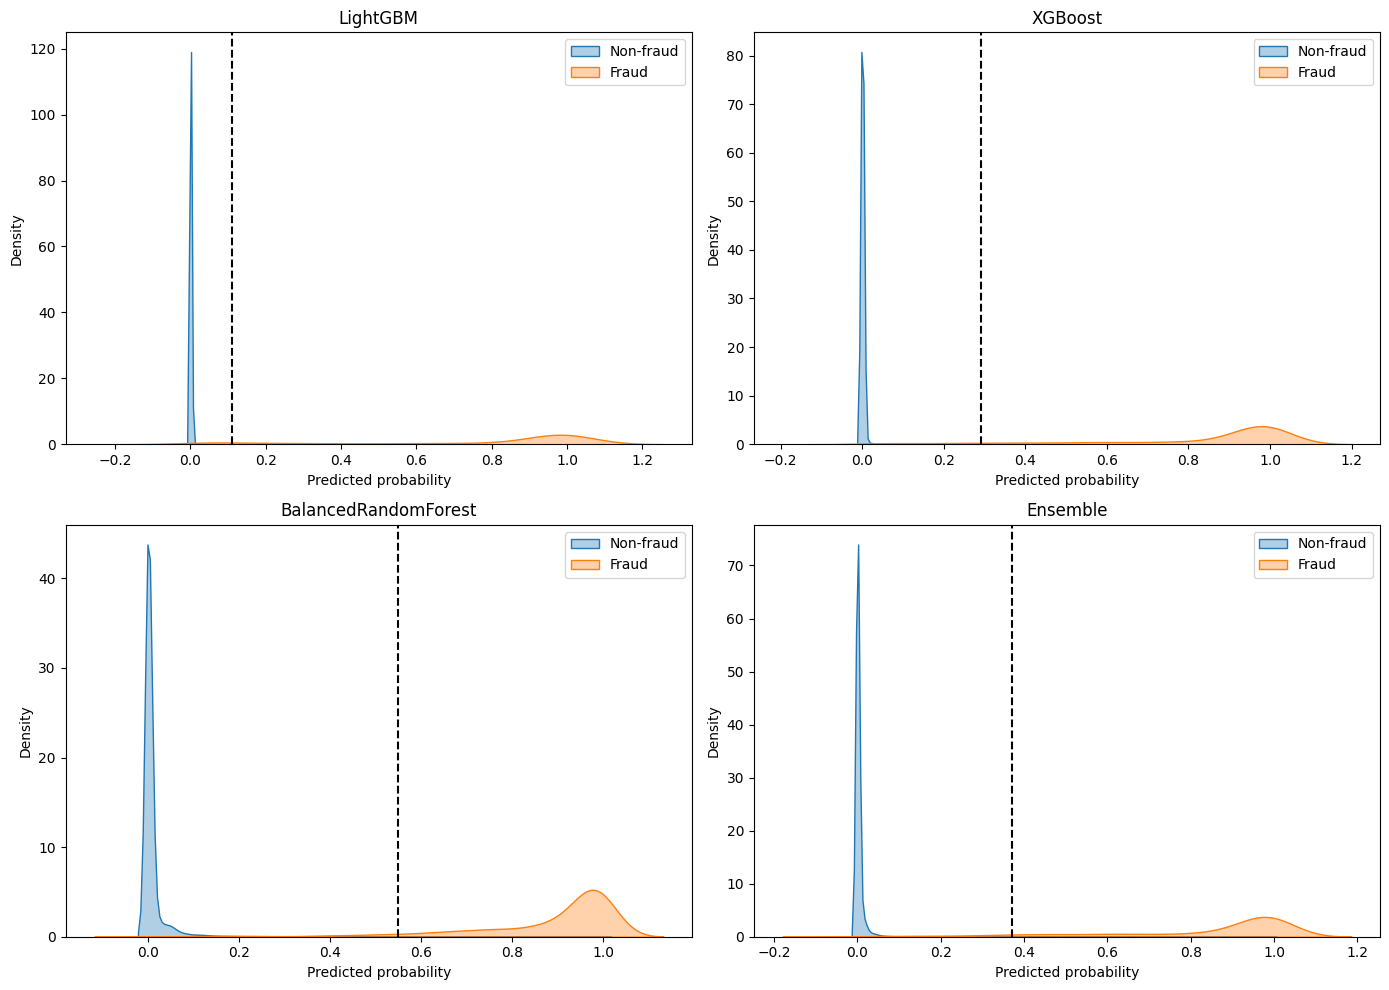

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, model_name in zip(axes, test_prob_dict.keys()):
    fraud_probs = test_prob_dict[model_name][y_test == 1]
    nonfraud_probs = test_prob_dict[model_name][y_test == 0]

    sns.kdeplot(nonfraud_probs, label='Non-fraud', fill=True, common_norm=False, alpha=0.35, ax=ax)
    sns.kdeplot(fraud_probs, label='Fraud', fill=True, common_norm=False, alpha=0.35, ax=ax)
    ax.axvline(best_thresholds[model_name], color='black', linestyle='--', linewidth=1.5)
    ax.set_title(model_name)
    ax.set_xlabel('Predicted probability')
    ax.set_ylabel('Density')
    ax.legend()

plt.tight_layout()
plt.show()

### 3.6 Model Comparison Bar Chart

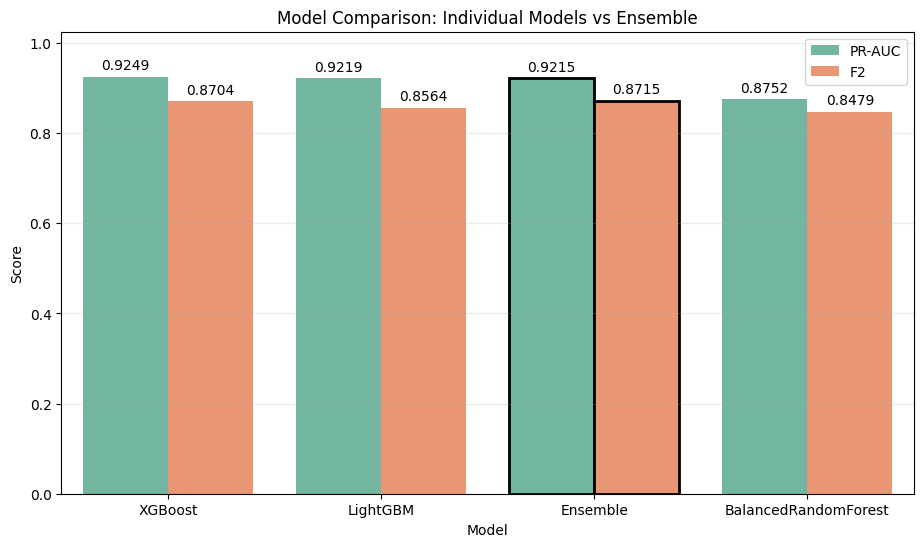

,Model,PR-AUC,ROC-AUC,F2,Threshold,Precision,Recall
0,XGBoost,0.924936,0.998865,0.870414,0.29,0.699060,0.927235
1,LightGBM,0.921923,0.998792,0.856359,0.11,0.696414,0.908524
2,Ensemble,0.921461,0.998665,0.871488,0.37,0.714746,0.922037
3,BalancedRandomForest,0.875167,0.998051,0.847904,0.55,0.613188,0.937630


In [14]:
plot_df = comparison_df[['Model', 'PR-AUC', 'F2']].melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(11, 6))
ax = sns.barplot(data=plot_df, x='Model', y='Score', hue='Metric', palette='Set2')

for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=3)

for patch, (_, row) in zip(ax.patches, plot_df.iterrows()):
    if row['Model'] == 'Ensemble':
        patch.set_edgecolor('black')
        patch.set_linewidth(2)

plt.title('Model Comparison: Individual Models vs Ensemble')
plt.xlabel('Model')
plt.ylabel('Score')
plt.ylim(0, min(1.05, plot_df['Score'].max() + 0.1))
plt.grid(axis='y', alpha=0.25)
plt.legend()
plt.show()

comparison_df